<a href="https://colab.research.google.com/github/HittersLab/jubilee-trp3-metocean-fatigue-analysis/blob/main/03_Metocean_Fatigue_Correlation_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# CASE EXERCISE 3: METOCEAN-FATIGUE CORRELATION MODEL

## Introduction

This case exercise develops a metocean-fatigue correlation model using the JONSWAP wave spectrum and spectral fatigue analysis.

The objective is to investigate how environmental conditions, particularly significant wave height, peak spectral period, current speed and wind speed, relate to fatigue damage accumulation in a subsea riser.

The analysis follows the five-stage metocean-to-fatigue pipeline described in Section 3.6 of the course material.

## Objectives

1. Generate wave energy spectra using the JONSWAP spectrum.
2. Convert wave spectra into structural stress response spectra using a transfer function.
3. Calculate spectral moments and estimate hourly fatigue damage.
4. Apply an S-N curve and the narrow-band fatigue approximation.
5. Develop a reusable pipeline for processing hourly metocean observations.

## Dataset Description

The analysis uses the Jubilee TRP3 synthetic metocean dataset.

The dataset contains 8,760 hourly observations covering January to December 2025.

The environmental parameters include:

- Significant wave height (Hs).
- Peak spectral period (Tp).
- Current speed.
- Wind speed.
- Timestamp.

**Important:** The dataset is synthetic and is intended for educational modelling. It does not represent verified operational measurements from the Jubilee field.

## Methodology

The pipeline consists of five stages:

1. Sea-state characterisation.
2. JONSWAP wave spectrum generation.
3. Structural stress response calculation.
4. Spectral fatigue damage calculation.
5. Fatigue damage estimation using the S-N curve and narrow-band approximation.

## Engineering Assumptions and Limitations

Section 3.6 describes the use of a simplified linear structural transfer function but does not provide its numerical equation or calibration coefficients.

Therefore, the transfer function must be supplied or explicitly defined as an illustrative educational assumption before numerical fatigue damage can be interpreted as a structural response.

The results from this exercise must not be treated as approved engineering design or operational integrity predictions.



## Question 1: JONSWAP-Based Spectral Fatigue Pipeline

### 1. Sea-State Characterisation

Sea states are characterised using significant wave height (Hs) and peak spectral period (Tp).

These parameters describe the wave environment and provide the inputs required for generating the wave energy spectrum.

### 2. Wave Spectrum Generation

The JONSWAP spectrum is used to represent the distribution of wave energy across different frequencies.

The peak enhancement factor (gamma) is set to 2.5 in the dataset-building function, following the Gulf of Guinea example in the course material.

### 3. Structural Response

The structural transfer function converts the wave energy spectrum into a stress response spectrum.

The transfer function is represented by:

Stress Spectrum = Wave Spectrum × Transfer Function²

The actual transfer function must be obtained or calibrated for the structure being analysed.

### 4. Spectral Fatigue Calculation

The spectral moments are calculated as:

- m0: Zeroth spectral moment.
- m2: Second spectral moment.
- m4: Fourth spectral moment.

The narrow-band approximation uses m0 and m2 to estimate RMS stress and zero-crossing frequency.

### 5. Fatigue Damage Estimation

The fatigue damage calculation uses the S-N curve parameters supplied in Section 3.6:

- Log A = 11.764
- S-N slope (m) = 3.0
- Observation duration = 1 hour

The calculation follows the narrow-band fatigue damage equation supplied in the course material.

### Expected Outcome

A reusable Python pipeline containing:

- JONSWAP wave spectrum generation.
- Spectral fatigue damage calculation.
- Structural transfer function interface.
- Metocean-fatigue dataset builder.


In [1]:

# Question 1: JONSWAP-Based Spectral Fatigue Pipeline

# Step 1: Import the required libraries
import numpy as np
import pandas as pd
import math

from scipy.special import gamma as gamma_fn


# Step 2: Define the JONSWAP wave spectrum function
def jonswap_spectrum(
    hs: float,
    tp: float,
    frequencies: np.ndarray,
    gamma: float = 3.3
) -> np.ndarray:
    """
    Generate the JONSWAP wave energy spectrum.

    Parameters:
        hs: Significant wave height (m).
        tp: Peak spectral period (s).
        frequencies: Array of frequencies (Hz).
        gamma: Peak enhancement factor.
               Default is 3.3 for North Sea.
               Use 2.0-2.5 for Gulf of Guinea.
    """

    # Calculate peak frequency
    fp = 1.0 / tp

    # Pierson-Moskowitz constants
    alpha = 0.0081
    g = 9.81

    # Calculate Pierson-Moskowitz base spectrum
    pm = (
        alpha * g**2 / (2 * np.pi)**4 / frequencies**5
        * np.exp(-5/4 * (fp / frequencies)**4)
    )

    # Calculate JONSWAP peak enhancement
    sigma = np.where(frequencies <= fp, 0.07, 0.09)

    peak_factor = gamma ** np.exp(
        -0.5 * ((frequencies - fp) / (sigma * fp))**2
    )

    # Generate JONSWAP spectrum
    S = pm * peak_factor

    # Calculate spectral zeroth moment
    m0 = np.trapz(S, frequencies)

    # Calculate significant wave height represented by spectrum
    hs_actual = 4 * np.sqrt(m0)

    # Scale spectrum to match the supplied significant wave height
    S *= (hs / hs_actual)**2

    return S


# Step 3: Define the spectral fatigue damage function
def spectral_fatigue_damage(
    stress_spectrum: np.ndarray,
    frequencies: np.ndarray,
    sn_log_a: float = 11.764,
    sn_m: float = 3.0,
    duration_hours: float = 1.0
) -> float:
    """
    Calculate fatigue damage from stress response spectrum.

    Uses the narrow-band approximation (Rayleigh distribution of peaks).
    """

    # Calculate spectral moments
    m0 = np.trapz(stress_spectrum, frequencies)
    m2 = np.trapz(stress_spectrum * frequencies**2, frequencies)
    m4 = np.trapz(stress_spectrum * frequencies**4, frequencies)

    # Calculate zero-crossing frequency
    f0 = math.sqrt(m2 / m0)

    # Calculate number of cycles during the observation period
    n_cycles = f0 * duration_hours * 3600

    # Convert S-N curve intercept from logarithmic form
    a = 10**sn_log_a

    # Calculate RMS stress
    sigma_s = math.sqrt(m0)

    # Calculate narrow-band fatigue damage
    damage = (
        (n_cycles / a)
        * (2 * math.sqrt(2) * sigma_s)**sn_m
        * gamma_fn(1 + sn_m / 2)
    )

    return damage


# Step 4: Define the metocean-fatigue correlation dataset builder
def build_fatigue_correlation_dataset(
    metocean_df: pd.DataFrame,
    transfer_function: callable,
    sn_params: dict
) -> pd.DataFrame:
    """
    Build a dataset pairing metocean conditions with fatigue damage.
    """

    results = []

    # Define frequency range
    freqs = np.linspace(0.02, 0.5, 200)

    # Process each metocean observation
    for _, row in metocean_df.iterrows():

        # Generate wave energy spectrum
        wave_S = jonswap_spectrum(
            row["hs_m"],
            row["tp_s"],
            freqs,
            gamma=2.5
        )

        # Apply structural transfer function
        tf = transfer_function(
            freqs,
            row.get("current_ms", 0)
        )

        # Calculate structural stress spectrum
        stress_S = wave_S * tf**2

        # Calculate hourly fatigue damage
        damage = spectral_fatigue_damage(
            stress_S,
            freqs,
            sn_log_a=sn_params["log_a"],
            sn_m=sn_params["m"],
            duration_hours=1.0
        )

        # Store metocean and fatigue results
        results.append({
            "timestamp": row["timestamp"],
            "hs_m": row["hs_m"],
            "tp_s": row["tp_s"],
            "current_ms": row.get("current_ms", 0),
            "wind_ms": row.get("wind_ms", 0),
            "hourly_damage": damage
        })

    return pd.DataFrame(results)


# Step 5: Define S-N curve parameters
sn_params = {
    "log_a": 11.764,
    "m": 3.0
}


# Step 6: Define the frequency array
frequencies = np.linspace(0.02, 0.5, 200)


# Step 7: Confirm that the functions are defined
print("JONSWAP-based spectral fatigue pipeline created successfully.")

print("\nPipeline components:")
print("1. JONSWAP wave spectrum generation")
print("2. Spectral fatigue damage calculation")
print("3. Structural transfer function interface")
print("4. Metocean-fatigue correlation dataset builder")

print("\nEngineering parameters:")
print("JONSWAP gamma: 2.5 in correlation dataset builder")
print("S-N curve log A:", sn_params["log_a"])
print("S-N curve slope:", sn_params["m"])
print("Duration per observation: 1 hour")
print("Frequency range: 0.02 - 0.5 Hz")
print("Frequency points:", len(frequencies))


JONSWAP-based spectral fatigue pipeline created successfully.

Pipeline components:
1. JONSWAP wave spectrum generation
2. Spectral fatigue damage calculation
3. Structural transfer function interface
4. Metocean-fatigue correlation dataset builder

Engineering parameters:
JONSWAP gamma: 2.5 in correlation dataset builder
S-N curve log A: 11.764
S-N curve slope: 3.0
Duration per observation: 1 hour
Frequency range: 0.02 - 0.5 Hz
Frequency points: 200



### Technical Note: Spectral Moments

The spectral fatigue calculation follows the narrow-band approximation presented in Section 3.6.2.

Three spectral moments are calculated: m0, m2 and m4.

The zeroth spectral moment (m0) is used to calculate the RMS stress, while the second spectral moment (m2) is used to estimate the zero-crossing frequency and number of loading cycles.

The fourth spectral moment (m4) is also calculated in the supplied course function but is not used in the provided narrow-band fatigue damage equation.

The implementation retains all three moments to remain consistent with the course material.



## Question 2: Hourly Fatigue Damage Calculation

### Objective

Calculate hourly fatigue damage for the complete year of Jubilee TRP3 metocean observations using the spectral fatigue pipeline developed in Question 1.

### Methodology

The calculation will process each hourly metocean observation independently.

For each observation:

1. Extract significant wave height (Hs) and peak spectral period (Tp).
2. Generate the JONSWAP wave energy spectrum.
3. Apply the structural transfer function.
4. Calculate the stress spectral moments.
5. Estimate the number of loading cycles.
6. Calculate hourly fatigue damage using the specified S-N curve.

### Expected Output

A processed dataset containing:

- Timestamp.
- Significant wave height.
- Peak spectral period.
- Current speed.
- Wind speed.
- Hourly fatigue damage.

The expected dataset contains 8,760 hourly observations covering January to December 2025.

### Engineering Limitation

The course material describes a simplified linear structural transfer function but does not provide its numerical equation or calibration coefficients.

A verified transfer function is therefore required before the hourly fatigue damage results can be interpreted as structural fatigue estimates.


In [2]:

# ============================================================
# CASE EXERCISE 3
# QUESTION 2: FULL-YEAR HOURLY FATIGUE DAMAGE CALCULATION
# ============================================================


# STEP 1: IMPORT REQUIRED LIBRARIES

import numpy as np
import pandas as pd
import math

from scipy.special import gamma as gamma_fn
from google.colab import files

print("Libraries imported successfully.")


# STEP 2: UPLOAD THE METOCEAN DATASET

print("\nUpload the Jubilee TRP3 metocean CSV dataset.")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No dataset was uploaded.")

file_name = next(iter(uploaded))

metocean_df = pd.read_csv(file_name)

print("\nDataset uploaded successfully.")
print("Filename:", file_name)


# STEP 3: PREPARE THE DATASET

column_mapping = {
    "Hs_m": "hs_m",
    "Tp_s": "tp_s",
    "current_speed_ms": "current_ms",
    "wind_speed_ms": "wind_ms"
}

metocean_df = metocean_df.rename(
    columns=column_mapping
)

metocean_df["timestamp"] = pd.to_datetime(
    metocean_df["timestamp"],
    errors="coerce"
)

required_columns = [
    "timestamp",
    "hs_m",
    "tp_s",
    "current_ms",
    "wind_ms"
]

missing_columns = [
    col for col in required_columns
    if col not in metocean_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert environmental data to numeric
for col in ["hs_m", "tp_s", "current_ms", "wind_ms"]:
    metocean_df[col] = pd.to_numeric(
        metocean_df[col],
        errors="coerce"
    )

# Check missing values
if metocean_df[required_columns].isnull().any().any():
    raise ValueError(
        "Missing or invalid values detected in the dataset."
    )

# Check physically invalid values
if (metocean_df["hs_m"] < 0).any():
    raise ValueError("Wave height cannot be negative.")

if (metocean_df["tp_s"] <= 0).any():
    raise ValueError("Peak period must be positive.")

# Sort observations by timestamp
metocean_df = metocean_df.sort_values(
    "timestamp"
).reset_index(drop=True)

print("\nDATASET INSPECTION")
print("------------------")

print("Dataset shape:", metocean_df.shape)
print("Total observations:", len(metocean_df))

print("\nFirst five observations:")
display(metocean_df[required_columns].head())

print("\nObservation period:")
print("Start:", metocean_df["timestamp"].min())
print("End:", metocean_df["timestamp"].max())

print("\nMissing values:")
print(metocean_df[required_columns].isnull().sum())


# STEP 4: DEFINE THE JONSWAP WAVE SPECTRUM FUNCTION

def jonswap_spectrum(
    hs: float,
    tp: float,
    frequencies: np.ndarray,
    gamma: float = 3.3
) -> np.ndarray:

    """
    Generate the JONSWAP wave energy spectrum.
    """

    fp = 1.0 / tp

    alpha = 0.0081
    g = 9.81

    # Pierson-Moskowitz base spectrum
    pm = (
        alpha * g**2 / (2 * np.pi)**4 / frequencies**5
        * np.exp(-5/4 * (fp / frequencies)**4)
    )

    # JONSWAP peak enhancement
    sigma = np.where(
        frequencies <= fp,
        0.07,
        0.09
    )

    peak_factor = gamma ** np.exp(
        -0.5 * ((frequencies - fp) / (sigma * fp))**2
    )

    # Generate JONSWAP spectrum
    S = pm * peak_factor

    # Calculate zeroth spectral moment
    m0 = np.trapezoid(S, frequencies)

    # Calculate significant wave height represented
    hs_actual = 4 * np.sqrt(m0)

    if hs_actual <= 0:
        raise ValueError("Invalid JONSWAP spectrum.")

    # Scale spectrum to match supplied wave height
    S *= (hs / hs_actual)**2

    return S


# STEP 5: DEFINE THE STRUCTURAL TRANSFER FUNCTION

def transfer_function(
    frequencies: np.ndarray,
    current_ms: float
) -> np.ndarray:

    """
    EDUCATIONAL PLACEHOLDER ONLY.

    A constant response factor of 1.0 is used
    to demonstrate the computational pipeline.

    This is NOT a calibrated structural transfer
    function for Jubilee TRP3.
    """

    return np.ones_like(frequencies)


# STEP 6: DEFINE THE SPECTRAL FATIGUE DAMAGE FUNCTION

def spectral_fatigue_damage(
    stress_spectrum: np.ndarray,
    frequencies: np.ndarray,
    sn_log_a: float = 11.764,
    sn_m: float = 3.0,
    duration_hours: float = 1.0
) -> float:

    """
    Calculate fatigue damage using the narrow-band
    approximation supplied in Section 3.6.
    """

    # Calculate spectral moments using NumPy trapezoid
    m0 = np.trapezoid(
        stress_spectrum,
        frequencies
    )

    m2 = np.trapezoid(
        stress_spectrum * frequencies**2,
        frequencies
    )

    m4 = np.trapezoid(
        stress_spectrum * frequencies**4,
        frequencies
    )

    # Check spectral moments
    if m0 <= 0 or m2 < 0:
        raise ValueError("Invalid spectral moments.")

    # Calculate zero-crossing frequency
    f0 = math.sqrt(m2 / m0)

    # Calculate number of loading cycles
    n_cycles = f0 * duration_hours * 3600

    # Convert S-N curve intercept
    a = 10**sn_log_a

    # Calculate RMS stress
    sigma_s = math.sqrt(m0)

    # Calculate narrow-band fatigue damage
    damage = (
        (n_cycles / a)
        * (2 * math.sqrt(2) * sigma_s)**sn_m
        * gamma_fn(1 + sn_m / 2)
    )

    return damage


# STEP 7: DEFINE S-N CURVE PARAMETERS

sn_params = {
    "log_a": 11.764,
    "m": 3.0
}


# STEP 8: DEFINE FREQUENCY RANGE

frequencies = np.linspace(
    0.02,
    0.5,
    200
)


# STEP 9: BUILD THE HOURLY FATIGUE DATASET

def build_fatigue_correlation_dataset(
    metocean_df: pd.DataFrame,
    transfer_function: callable,
    sn_params: dict
) -> pd.DataFrame:

    """
    Process hourly metocean observations and calculate
    illustrative spectral fatigue damage.
    """

    results = []

    for _, row in metocean_df.iterrows():

        # Generate JONSWAP wave spectrum
        wave_S = jonswap_spectrum(
            row["hs_m"],
            row["tp_s"],
            frequencies,
            gamma=2.5
        )

        # Apply structural transfer function
        tf = transfer_function(
            frequencies,
            row["current_ms"]
        )

        # Calculate stress response spectrum
        stress_S = wave_S * tf**2

        # Calculate hourly fatigue damage
        damage = spectral_fatigue_damage(
            stress_S,
            frequencies,
            sn_log_a=sn_params["log_a"],
            sn_m=sn_params["m"],
            duration_hours=1.0
        )

        # Store hourly results
        results.append({
            "timestamp": row["timestamp"],
            "hs_m": row["hs_m"],
            "tp_s": row["tp_s"],
            "current_ms": row["current_ms"],
            "wind_ms": row["wind_ms"],
            "hourly_damage": damage
        })

    return pd.DataFrame(results)


# STEP 10: CALCULATE HOURLY FATIGUE DAMAGE

fatigue_df = build_fatigue_correlation_dataset(
    metocean_df,
    transfer_function,
    sn_params
)

# Calculate cumulative damage
fatigue_df["cumulative_damage"] = (
    fatigue_df["hourly_damage"].cumsum()
)


# STEP 11: DISPLAY FATIGUE RESULTS

print("\nHOURLY FATIGUE CALCULATION COMPLETED")
print("------------------------------------")

print("Total observations:", len(fatigue_df))

print(
    "Total hourly damage:",
    fatigue_df["hourly_damage"].sum()
)

print(
    "Mean hourly damage:",
    fatigue_df["hourly_damage"].mean()
)

print(
    "Maximum hourly damage:",
    fatigue_df["hourly_damage"].max()
)

print(
    "Final cumulative damage:",
    fatigue_df["cumulative_damage"].iloc[-1]
)

print("\nFirst five fatigue observations:")
display(fatigue_df.head())


# STEP 12: SAVE THE PROCESSED DATASET

output_file = "jubilee_trp3_hourly_fatigue_damage.csv"

fatigue_df.to_csv(
    output_file,
    index=False
)

print("\nProcessed dataset saved successfully.")
print("Filename:", output_file)


# STEP 13: DOWNLOAD THE PROCESSED DATASET

files.download(output_file)

print("\nQUESTION 2 COMPLETED SUCCESSFULLY.")


Libraries imported successfully.

Upload the Jubilee TRP3 metocean CSV dataset.


Saving jubilee_trp3_synthetic_metocean_1year.csv to jubilee_trp3_synthetic_metocean_1year.csv

Dataset uploaded successfully.
Filename: jubilee_trp3_synthetic_metocean_1year.csv

DATASET INSPECTION
------------------
Dataset shape: (8760, 8)
Total observations: 8760

First five observations:


,timestamp,hs_m,tp_s,current_ms,wind_ms
0,2025-01-01 00:00:00,1.151,9.506,0.460,3.711
1,2025-01-01 01:00:00,1.005,9.678,0.449,5.389
2,2025-01-01 02:00:00,1.308,9.942,0.484,4.649
3,2025-01-01 03:00:00,1.136,8.768,0.384,4.122
4,2025-01-01 04:00:00,1.222,7.180,0.462,7.837



Observation period:
Start: 2025-01-01 00:00:00
End: 2025-12-31 23:00:00

Missing values:
timestamp     0
hs_m          0
tp_s          0
current_ms    0
wind_ms       0
dtype: int64

HOURLY FATIGUE CALCULATION COMPLETED
------------------------------------
Total observations: 8760
Total hourly damage: 1.3378193702599723e-05
Mean hourly damage: 1.5271910619406076e-09
Maximum hourly damage: 2.0779504034706757e-08
Final cumulative damage: 1.3378193702599773e-05

First five fatigue observations:


,timestamp,hs_m,tp_s,current_ms,wind_ms,hourly_damage,cumulative_damage
0,2025-01-01 00:00:00,1.151,9.506,0.460,3.711,6.009733e-10,6.009733e-10
1,2025-01-01 01:00:00,1.005,9.678,0.449,5.389,3.932702e-10,9.942435e-10
2,2025-01-01 02:00:00,1.308,9.942,0.484,4.649,8.449463e-10,1.839190e-09
3,2025-01-01 03:00:00,1.136,8.768,0.384,4.122,6.239179e-10,2.463108e-09
4,2025-01-01 04:00:00,1.222,7.180,0.462,7.837,9.361301e-10,3.399238e-09



Processed dataset saved successfully.
Filename: jubilee_trp3_hourly_fatigue_damage.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


QUESTION 2 COMPLETED SUCCESSFULLY.


## Question 3: Polynomial Regression Models for Fatigue Prediction

### Objective

Develop polynomial regression models of degrees 1, 2 and 3 to predict hourly fatigue damage using metocean variables.

### Methodology

The processed fatigue dataset from Question 2 will be used for model development.

The input features are:
- Significant wave height (`hs_m`)
- Peak wave period (`tp_s`)
- Current speed (`current_ms`)

The target variable is:
- Hourly fatigue damage (`hourly_damage`)

The dataset will be divided into training and testing subsets using an 80:20 split. Three polynomial regression models will be developed and evaluated using the coefficient of determination (R²) and Mean Absolute Error (MAE).

The results will be compared to identify which polynomial degree provides the best predictive performance.

### Expected Outcome

A comparison of degree 1, degree 2 and degree 3 polynomial regression models, showing their ability to predict fatigue damage from metocean conditions.

In [3]:

# QUESTION 3: POLYNOMIAL REGRESSION MODELS

import pandas as pd
import numpy as np

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Upload the processed fatigue dataset
print("Upload the Question 2 fatigue dataset.")

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

# 2. Inspect and prepare the dataset
required_columns = [
    "hs_m",
    "tp_s",
    "current_ms",
    "hourly_damage"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df = df[required_columns].copy()

df = df.replace([np.inf, -np.inf], np.nan).dropna()

if (df["hourly_damage"] < 0).any():
    raise ValueError("Hourly damage cannot be negative.")

if df["hourly_damage"].nunique() < 2:
    raise ValueError("The target variable must contain variation.")

X = df[["hs_m", "tp_s", "current_ms"]]
y = df["hourly_damage"]

print("\nDATASET PREPARATION")
print("-------------------")
print("Dataset shape:", df.shape)
print("Input features:", list(X.columns))
print("Target variable: hourly_damage")

# 3. Split the dataset into training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 4. Train polynomial regression models
results = []
trained_models = {}

for degree in [1, 2, 3]:

    model = Pipeline([
        ("polynomial", PolynomialFeatures(
            degree=degree,
            include_bias=False
        )),
        ("scaler", StandardScaler()),
        ("regression", LinearRegression())
    ])

    model.fit(X_train, y_train)

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Performance metrics
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    test_mae = mean_absolute_error(
        y_test,
        y_test_pred
    )

    results.append({
        "Polynomial Degree": degree,
        "Training R2": train_r2,
        "Testing R2": test_r2,
        "Testing MAE": test_mae
    })

    trained_models[degree] = model

# 5. Display model comparison
results_df = pd.DataFrame(results)

print("\nPOLYNOMIAL REGRESSION MODEL COMPARISON")
print("--------------------------------------")

print(results_df.to_string(index=False))

# 6. Identify the model with the highest test R2
best_model_row = results_df.loc[
    results_df["Testing R2"].idxmax()
]

best_degree = int(best_model_row["Polynomial Degree"])

print("\nBEST PERFORMING MODEL")
print("---------------------")
print("Polynomial degree:", best_degree)
print("Testing R2:", best_model_row["Testing R2"])
print("Testing MAE:", best_model_row["Testing MAE"])

# 7. Save model performance results
results_df.to_csv(
    "polynomial_regression_model_comparison.csv",
    index=False
)

print("\nModel comparison saved successfully.")

files.download(
    "polynomial_regression_model_comparison.csv"
)


Upload the Question 2 fatigue dataset.


Saving jubilee_trp3_hourly_fatigue_damage.csv to jubilee_trp3_hourly_fatigue_damage (1).csv

DATASET PREPARATION
-------------------
Dataset shape: (8760, 4)
Input features: ['hs_m', 'tp_s', 'current_ms']
Target variable: hourly_damage

POLYNOMIAL REGRESSION MODEL COMPARISON
--------------------------------------
 Polynomial Degree  Training R2  Testing R2  Testing MAE
                 1     0.856376    0.851846 4.583185e-10
                 2     0.998816    0.998683 3.843525e-11
                 3     0.999989    0.999988 3.607921e-12

BEST PERFORMING MODEL
---------------------
Polynomial degree: 3
Testing R2: 0.9999882990725962
Testing MAE: 3.607921093140316e-12

Model comparison saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Question 4: Five-Fold Cross-Validation and Residual Analysis

### Objective

Validate the polynomial regression models developed in Question 3 using five-fold cross-validation and residual analysis.

### Methodology

The three polynomial regression models (degrees 1, 2 and 3) will be evaluated using five-fold cross-validation.

The evaluation metrics are:

- **R²:** Measures how well the model explains variation in hourly fatigue damage.
- **MAE:** Measures the average absolute difference between predicted and actual fatigue damage.

The model with the strongest average cross-validation performance will be selected for residual analysis.

Residuals will be calculated as the difference between actual and predicted fatigue damage. Residual plots and descriptive statistics will be used to identify systematic prediction errors, possible bias and patterns that may indicate model weaknesses.

### Expected Outcome

A comparison of cross-validation performance across all three polynomial models, supported by residual analysis to assess prediction accuracy and model reliability.

Upload the Question 2 fatigue dataset.


Saving jubilee_trp3_hourly_fatigue_damage.csv to jubilee_trp3_hourly_fatigue_damage (2).csv

DATASET PREPARATION
-------------------
Dataset shape: (8760, 4)

FIVE-FOLD CROSS-VALIDATION RESULTS
----------------------------------
 Polynomial Degree  Mean CV R2  Std CV R2  Mean CV MAE   Std CV MAE
                 1    0.855487   0.010597 4.459745e-10 1.310555e-11
                 2    0.998760   0.000303 3.802549e-11 5.105730e-13
                 3    0.999988   0.000001 3.607410e-12 9.979737e-14

BEST MODEL BASED ON CROSS-VALIDATION
------------------------------------
Polynomial degree: 3

RESIDUAL ANALYSIS
-----------------
Mean residual: -1.8369170945264731e-13
Residual standard deviation: 6.270755974372976e-12
Residual MAE: 3.607921093140316e-12
Test R2: 0.9999882990725962


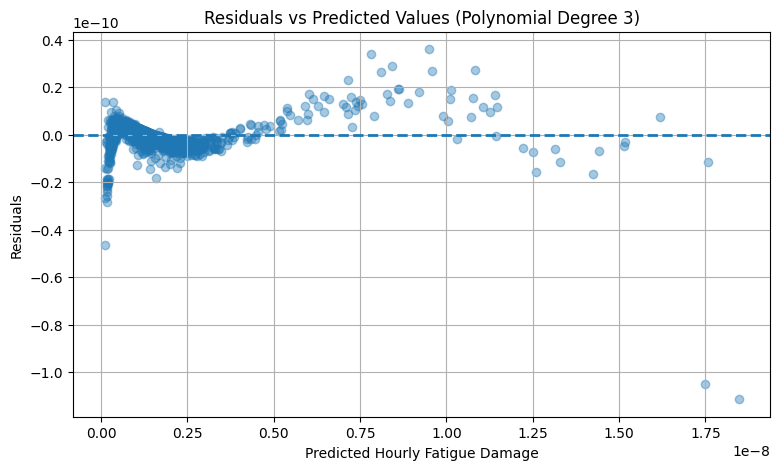

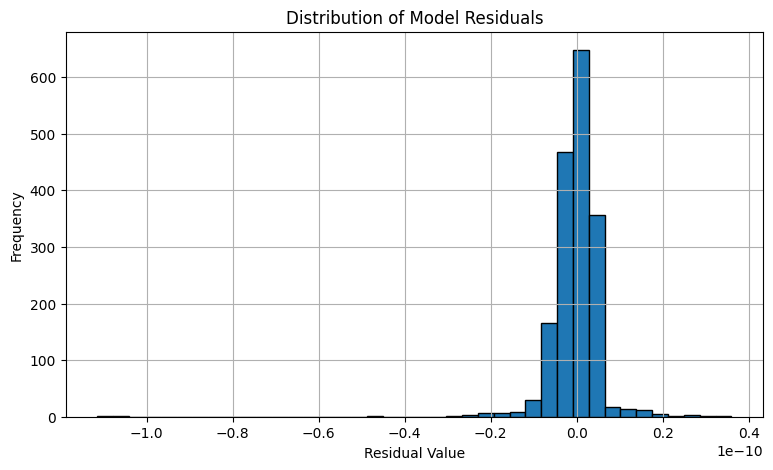


RESIDUAL PATTERN BY PREDICTION RANGE
------------------------------------
           prediction_group  mean_actual  mean_predicted  mean_residual  mean_absolute_residual
(-0.000999999894, 5.98e-10] 4.166995e-10    4.168713e-10  -1.718245e-13            4.307890e-12
       (5.98e-10, 9.36e-10] 7.623391e-10    7.593958e-10   2.943228e-12            3.073728e-12
       (9.36e-10, 1.34e-09] 1.145298e-09    1.144578e-09   7.205871e-13            1.851136e-12
       (1.34e-09, 1.95e-09] 1.630637e-09    1.632918e-09  -2.281305e-12            2.370365e-12
       (1.95e-09, 1.85e-08] 3.863807e-09    3.865931e-09  -2.123635e-12            6.426433e-12

QUESTION 4 OUTPUTS SAVED SUCCESSFULLY
-------------------------------------
1. five_fold_cross_validation_results.csv
2. fatigue_model_residuals.csv
3. residual_pattern_analysis.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


QUESTION 4 ANALYSIS COMPLETED.


In [4]:

# QUESTION 4: FIVE-FOLD CROSS-VALIDATION AND RESIDUAL ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score
)

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# --------------------------------------------------
# 1. UPLOAD AND PREPARE THE DATASET
# --------------------------------------------------

print("Upload the Question 2 fatigue dataset.")

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

required_columns = [
    "hs_m",
    "tp_s",
    "current_ms",
    "hourly_damage"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

df = df[required_columns].copy()

df = df.replace([np.inf, -np.inf], np.nan).dropna()

X = df[["hs_m", "tp_s", "current_ms"]]
y = df["hourly_damage"]

print("\nDATASET PREPARATION")
print("-------------------")
print("Dataset shape:", df.shape)

# --------------------------------------------------
# 2. DEFINE FIVE-FOLD CROSS-VALIDATION
# --------------------------------------------------

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# --------------------------------------------------
# 3. EVALUATE POLYNOMIAL MODELS
# --------------------------------------------------

cv_results = []
models = {}

for degree in [1, 2, 3]:

    model = Pipeline([
        ("polynomial", PolynomialFeatures(
            degree=degree,
            include_bias=False
        )),
        ("scaler", StandardScaler()),
        ("regression", LinearRegression())
    ])

    # Five-fold R2 scores
    r2_scores = cross_val_score(
        model,
        X,
        y,
        cv=kfold,
        scoring="r2"
    )

    # Five-fold MAE scores
    mae_scores = -cross_val_score(
        model,
        X,
        y,
        cv=kfold,
        scoring="neg_mean_absolute_error"
    )

    cv_results.append({
        "Polynomial Degree": degree,
        "Mean CV R2": np.mean(r2_scores),
        "Std CV R2": np.std(r2_scores),
        "Mean CV MAE": np.mean(mae_scores),
        "Std CV MAE": np.std(mae_scores)
    })

    models[degree] = model

# --------------------------------------------------
# 4. DISPLAY CROSS-VALIDATION RESULTS
# --------------------------------------------------

cv_results_df = pd.DataFrame(cv_results)

print("\nFIVE-FOLD CROSS-VALIDATION RESULTS")
print("----------------------------------")

print(cv_results_df.to_string(index=False))

# --------------------------------------------------
# 5. SELECT THE BEST MODEL USING MEAN CV R2
# --------------------------------------------------

best_degree = int(
    cv_results_df.loc[
        cv_results_df["Mean CV R2"].idxmax(),
        "Polynomial Degree"
    ]
)

print("\nBEST MODEL BASED ON CROSS-VALIDATION")
print("------------------------------------")
print("Polynomial degree:", best_degree)

# --------------------------------------------------
# 6. CREATE TRAINING AND TESTING DATA
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

best_model = models[best_degree]

best_model.fit(X_train, y_train)

# Generate predictions
y_pred = best_model.predict(X_test)

# Calculate residuals
residuals = y_test.to_numpy() - y_pred

# --------------------------------------------------
# 7. RESIDUAL STATISTICS
# --------------------------------------------------

residual_mean = np.mean(residuals)
residual_std = np.std(residuals)
residual_mae = mean_absolute_error(y_test, y_pred)

print("\nRESIDUAL ANALYSIS")
print("-----------------")
print("Mean residual:", residual_mean)
print("Residual standard deviation:", residual_std)
print("Residual MAE:", residual_mae)
print("Test R2:", r2_score(y_test, y_pred))

# --------------------------------------------------
# 8. RESIDUAL VS PREDICTED PLOT
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.4
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted Hourly Fatigue Damage")
plt.ylabel("Residuals")
plt.title(
    f"Residuals vs Predicted Values "
    f"(Polynomial Degree {best_degree})"
)

plt.grid(True)
plt.show()

# --------------------------------------------------
# 9. RESIDUAL DISTRIBUTION
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.hist(
    residuals,
    bins=40,
    edgecolor="black"
)

plt.xlabel("Residual Value")
plt.ylabel("Frequency")
plt.title("Distribution of Model Residuals")

plt.grid(True)
plt.show()

# --------------------------------------------------
# 10. IDENTIFY POSSIBLE SYSTEMATIC WEAKNESSES
# --------------------------------------------------

residual_analysis = pd.DataFrame({
    "actual_damage": y_test.to_numpy(),
    "predicted_damage": y_pred,
    "residual": residuals
})

residual_analysis["absolute_residual"] = np.abs(
    residual_analysis["residual"]
)

# Divide predictions into five groups
residual_analysis["prediction_group"] = pd.qcut(
    residual_analysis["predicted_damage"],
    q=5,
    duplicates="drop"
)

group_analysis = residual_analysis.groupby(
    "prediction_group",
    observed=True
).agg(
    mean_actual=("actual_damage", "mean"),
    mean_predicted=("predicted_damage", "mean"),
    mean_residual=("residual", "mean"),
    mean_absolute_residual=("absolute_residual", "mean")
).reset_index()

print("\nRESIDUAL PATTERN BY PREDICTION RANGE")
print("------------------------------------")
print(group_analysis.to_string(index=False))

# --------------------------------------------------
# 11. SAVE ASSESSMENT OUTPUTS
# --------------------------------------------------

cv_results_df.to_csv(
    "five_fold_cross_validation_results.csv",
    index=False
)

residual_analysis.to_csv(
    "fatigue_model_residuals.csv",
    index=False
)

group_analysis.to_csv(
    "residual_pattern_analysis.csv",
    index=False
)

print("\nQUESTION 4 OUTPUTS SAVED SUCCESSFULLY")
print("-------------------------------------")
print("1. five_fold_cross_validation_results.csv")
print("2. fatigue_model_residuals.csv")
print("3. residual_pattern_analysis.csv")

# Download the three output files
files.download("five_fold_cross_validation_results.csv")
files.download("fatigue_model_residuals.csv")
files.download("residual_pattern_analysis.csv")

print("\nQUESTION 4 ANALYSIS COMPLETED.")


### Discussion of Cross-Validation and Residual Analysis

The five-fold cross-validation results show that the degree 3 polynomial regression model achieved the best predictive performance, with a mean R² of 0.999988 and a mean MAE of 3.607410 × 10⁻¹².

The degree 3 model also recorded a very small standard deviation of 0.000001 in its cross-validation R² scores, indicating consistent performance across the five validation folds.

Residual analysis produced a mean residual of -1.836917 × 10⁻¹³, which is close to zero. This suggests that the model has little overall prediction bias on the test dataset.

The residual pattern analysis also showed relatively small prediction errors across the five prediction ranges. However, residual plots should be examined to identify any nonlinear patterns or changing error variance.

Overall, the degree 3 polynomial regression model provided the strongest predictive performance among the three models evaluated.

**Limitations:** The results are based on synthetic metocean data and fatigue estimates generated using a simplified structural transfer function. Random cross-validation also does not fully account for temporal dependence in hourly observations. Time-based validation and calibrated structural response data would be required before applying the model to real subsea integrity decisions.

## Question 5: Metocean-Fatigue Dashboard

### Objective

Develop a dashboard to visualise the relationship between metocean conditions and fatigue damage for the Jubilee TRP3 dataset.

### Dashboard Components

The dashboard will contain four visualisations:

1. **Monthly Damage Accumulation:** Displays the total calculated fatigue damage for each month.
2. **Hs vs. Fatigue Damage:** Shows the relationship between significant wave height and hourly fatigue damage.
3. **Predicted vs. Actual Damage:** Compares fatigue damage predicted by the selected degree 3 polynomial regression model with the calculated fatigue damage.
4. **Cumulative Damage Trajectory:** Displays the progressive accumulation of fatigue damage throughout the observation period.

### Methodology

The processed fatigue dataset from Question 2 will be used alongside the degree 3 polynomial regression model selected in Questions 3 and 4.

The dashboard will use Python, Pandas, Matplotlib and Scikit-learn to process the data, generate predictions and create the visualisations.

### Expected Outcome

An integrated metocean-fatigue dashboard showing monthly damage accumulation, wave height relationships, model prediction performance and cumulative fatigue damage throughout 2025.

Upload the Question 2 fatigue dataset.


Saving jubilee_trp3_hourly_fatigue_damage.csv to jubilee_trp3_hourly_fatigue_damage (4).csv

DATASET PREPARATION
-------------------
Dataset shape: (8760, 7)
Observation period:
Start: 2025-01-01 00:00:00
End: 2025-12-31 23:00:00

MONTHLY FATIGUE DAMAGE
----------------------
month_name  hourly_damage
       Jan   6.515196e-07
       Feb   1.264824e-06
       Mar   1.319227e-06
       Apr   1.301786e-06
       May   1.847375e-06
       Jun   1.561410e-06
       Jul   1.481688e-06
       Aug   1.095941e-06
       Sep   7.883320e-07
       Oct   9.563279e-07
       Nov   5.070030e-07
       Dec   6.027599e-07

DEGREE 3 MODEL PERFORMANCE
--------------------------
Testing R2: 0.9999882990725962
Testing MAE: 3.607921093140316e-12


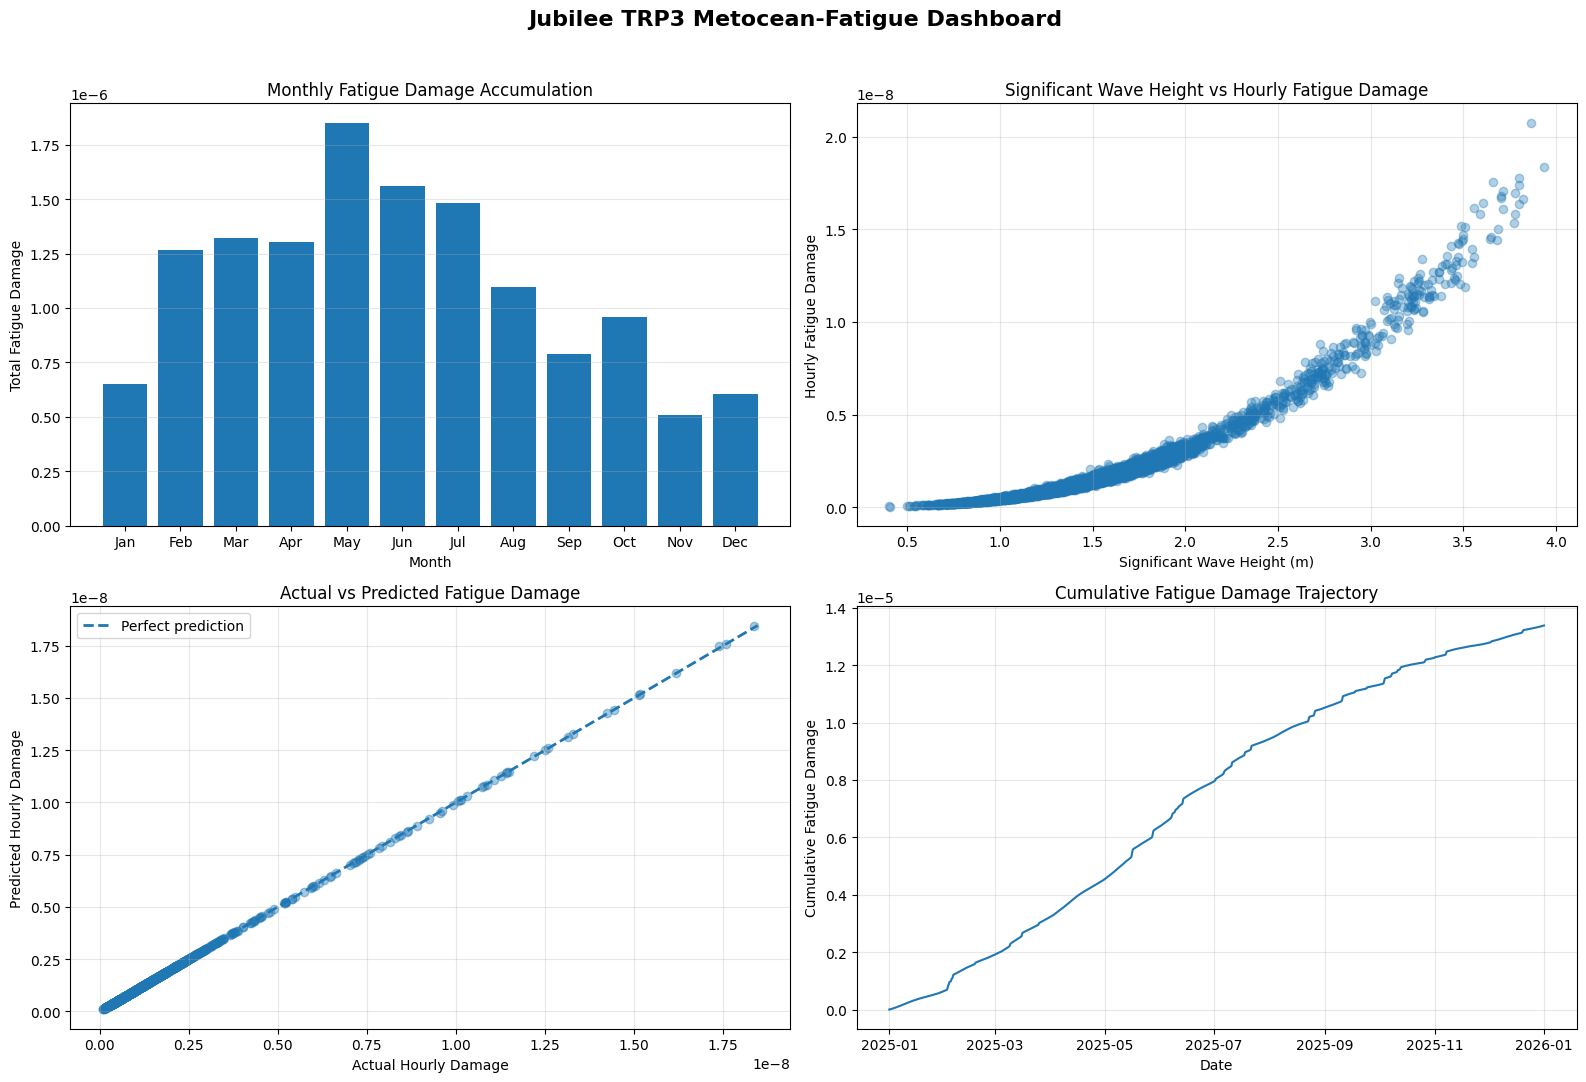


DASHBOARD EXPORT COMPLETED
--------------------------
1. monthly_fatigue_damage.csv
2. actual_vs_predicted_fatigue_damage.csv
3. jubilee_trp3_dashboard_dataset.csv
4. jubilee_trp3_metocean_fatigue_dashboard.png

FINAL DASHBOARD SUMMARY
-----------------------
Total hourly observations: 8760
Total annual fatigue damage: 1.3378193702599723e-05
Final cumulative damage: 1.3378193702599773e-05
Polynomial model degree: 3
Testing R2: 0.9999882990725962

QUESTION 5 COMPLETED SUCCESSFULLY.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

# ============================================================
# QUESTION 5: METOCEAN-FATIGUE DASHBOARD
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# ------------------------------------------------------------
# 1. UPLOAD THE PROCESSED FATIGUE DATASET
# ------------------------------------------------------------

print("Upload the Question 2 fatigue dataset.")

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

# ------------------------------------------------------------
# 2. CHECK AND PREPARE THE DATASET
# ------------------------------------------------------------

required_columns = [
    "timestamp",
    "hs_m",
    "tp_s",
    "current_ms",
    "hourly_damage"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna(subset=required_columns)

df = df.sort_values("timestamp").reset_index(drop=True)

if df.empty:
    raise ValueError("The dataset contains no valid observations.")

if (df["hourly_damage"] < 0).any():
    raise ValueError("Hourly damage cannot be negative.")

print("\nDATASET PREPARATION")
print("-------------------")
print("Dataset shape:", df.shape)
print("Observation period:")
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())

# ------------------------------------------------------------
# 3. CALCULATE MONTHLY DAMAGE ACCUMULATION
# ------------------------------------------------------------

df["month"] = df["timestamp"].dt.month

monthly_damage = (
    df.groupby("month")["hourly_damage"]
    .sum()
    .reset_index()
)

monthly_damage["month_name"] = pd.to_datetime(
    monthly_damage["month"],
    format="%m"
).dt.strftime("%b")

print("\nMONTHLY FATIGUE DAMAGE")
print("----------------------")
print(
    monthly_damage[
        ["month_name", "hourly_damage"]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 4. PREPARE INPUT FEATURES AND TARGET
# ------------------------------------------------------------

features = [
    "hs_m",
    "tp_s",
    "current_ms"
]

X = df[features]

y = df["hourly_damage"]

# ------------------------------------------------------------
# 5. TRAIN THE DEGREE 3 POLYNOMIAL MODEL
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

degree_3_model = Pipeline([
    (
        "polynomial",
        PolynomialFeatures(
            degree=3,
            include_bias=False
        )
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regression",
        LinearRegression()
    )
])

degree_3_model.fit(X_train, y_train)

# Generate test predictions
y_pred = degree_3_model.predict(X_test)

# Evaluate model
test_r2 = r2_score(y_test, y_pred)

test_mae = mean_absolute_error(
    y_test,
    y_pred
)

print("\nDEGREE 3 MODEL PERFORMANCE")
print("--------------------------")
print("Testing R2:", test_r2)
print("Testing MAE:", test_mae)

# ------------------------------------------------------------
# 6. CREATE ACTUAL VS PREDICTED DATA
# ------------------------------------------------------------

prediction_results = pd.DataFrame({
    "actual_damage": y_test.to_numpy(),
    "predicted_damage": y_pred
})

# ------------------------------------------------------------
# 7. CALCULATE CUMULATIVE DAMAGE
# ------------------------------------------------------------

df["cumulative_damage"] = (
    df["hourly_damage"].cumsum()
)

# ------------------------------------------------------------
# 8. CREATE DASHBOARD WITH FOUR VISUALISATIONS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11)
)

fig.suptitle(
    "Jubilee TRP3 Metocean-Fatigue Dashboard",
    fontsize=16,
    fontweight="bold"
)

# ------------------------------------------------------------
# PLOT 1: MONTHLY DAMAGE ACCUMULATION
# ------------------------------------------------------------

axes[0, 0].bar(
    monthly_damage["month_name"],
    monthly_damage["hourly_damage"]
)

axes[0, 0].set_title(
    "Monthly Fatigue Damage Accumulation"
)

axes[0, 0].set_xlabel("Month")

axes[0, 0].set_ylabel(
    "Total Fatigue Damage"
)

axes[0, 0].grid(
    axis="y",
    alpha=0.3
)

# ------------------------------------------------------------
# PLOT 2: SIGNIFICANT WAVE HEIGHT VS DAMAGE
# ------------------------------------------------------------

axes[0, 1].scatter(
    df["hs_m"],
    df["hourly_damage"],
    alpha=0.35
)

axes[0, 1].set_title(
    "Significant Wave Height vs Hourly Fatigue Damage"
)

axes[0, 1].set_xlabel(
    "Significant Wave Height (m)"
)

axes[0, 1].set_ylabel(
    "Hourly Fatigue Damage"
)

axes[0, 1].grid(alpha=0.3)

# ------------------------------------------------------------
# PLOT 3: PREDICTED VS ACTUAL DAMAGE
# ------------------------------------------------------------

axes[1, 0].scatter(
    prediction_results["actual_damage"],
    prediction_results["predicted_damage"],
    alpha=0.4
)

# Reference line representing perfect predictions
minimum_value = min(
    prediction_results["actual_damage"].min(),
    prediction_results["predicted_damage"].min()
)

maximum_value = max(
    prediction_results["actual_damage"].max(),
    prediction_results["predicted_damage"].max()
)

axes[1, 0].plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

axes[1, 0].set_title(
    "Actual vs Predicted Fatigue Damage"
)

axes[1, 0].set_xlabel(
    "Actual Hourly Damage"
)

axes[1, 0].set_ylabel(
    "Predicted Hourly Damage"
)

axes[1, 0].legend()

axes[1, 0].grid(alpha=0.3)

# ------------------------------------------------------------
# PLOT 4: CUMULATIVE DAMAGE TRAJECTORY
# ------------------------------------------------------------

axes[1, 1].plot(
    df["timestamp"],
    df["cumulative_damage"],
    linewidth=1.5
)

axes[1, 1].set_title(
    "Cumulative Fatigue Damage Trajectory"
)

axes[1, 1].set_xlabel("Date")

axes[1, 1].set_ylabel(
    "Cumulative Fatigue Damage"
)

axes[1, 1].grid(alpha=0.3)

# Improve spacing and layout
plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

# ------------------------------------------------------------
# 9. SAVE THE DASHBOARD IMAGE
# ------------------------------------------------------------

plt.savefig(
    "jubilee_trp3_metocean_fatigue_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. EXPORT DASHBOARD DATA
# ------------------------------------------------------------

monthly_damage.to_csv(
    "monthly_fatigue_damage.csv",
    index=False
)

prediction_results.to_csv(
    "actual_vs_predicted_fatigue_damage.csv",
    index=False
)

df.to_csv(
    "jubilee_trp3_dashboard_dataset.csv",
    index=False
)

print("\nDASHBOARD EXPORT COMPLETED")
print("--------------------------")

print("1. monthly_fatigue_damage.csv")
print("2. actual_vs_predicted_fatigue_damage.csv")
print("3. jubilee_trp3_dashboard_dataset.csv")
print("4. jubilee_trp3_metocean_fatigue_dashboard.png")

print("\nFINAL DASHBOARD SUMMARY")
print("-----------------------")

print("Total hourly observations:", len(df))

print(
    "Total annual fatigue damage:",
    df["hourly_damage"].sum()
)

print(
    "Final cumulative damage:",
    df["cumulative_damage"].iloc[-1]
)

print("Polynomial model degree: 3")

print("Testing R2:", test_r2)

print("\nQUESTION 5 COMPLETED SUCCESSFULLY.")

# ------------------------------------------------------------
# 11. DOWNLOAD THE OUTPUT FILES
# ------------------------------------------------------------

files.download("monthly_fatigue_damage.csv")

files.download("actual_vs_predicted_fatigue_damage.csv")

files.download("jubilee_trp3_dashboard_dataset.csv")

files.download("jubilee_trp3_metocean_fatigue_dashboard.png")
